# 04 — Linear-combination ground cost over the 96 SBS channels (approach 1)

Companion to `03_cost_matrix_graph.ipynb`. Here the cost between two channels `5'[REF>ALT]3'` is a **weighted sum of per-component costs**:

$$C_{ij} = a_5\, d_5(5'_i, 5'_j) \;+\; a_{\text{sub}}\, d_{\text{sub}}(\text{sub}_i, \text{sub}_j) \;+\; a_3\, d_3(3'_i, 3'_j)$$

- $d_5, d_3$ are 4×4 tables over the flanking bases, $d_{\text{sub}}$ a 6×6 table over the substitution classes.
- $a_5, a_{\text{sub}}, a_3$ set how much each component matters.

The simplest choice, indicator tables ($d=1$ if the component differs), gives a weighted Hamming distance. The tables can also carry biology: a transition/transversion distinction for the flanks, a structured substitution table, or the same energy CSVs used in `03` (`data/energy/`).

**Metric property.** A sum of metrics with positive weights is a metric. Each component table is therefore checked, and if a table breaks the triangle inequality (possible with energy tables) it is replaced by its shortest-path closure (`METRIC_CLOSURE = True`), so the final $C$ is a valid Wasserstein ground cost.

**Difference to approach 2.** Every component contributes independently: the cost of changing the 3' base is the same whatever the substitution is, so context effects such as CpG cannot be expressed here. `03` §4 shows that the graph reduces exactly to this notebook when its edge weights are uniform per component.

In [1]:
import json
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import MDS

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Resolve data/ whether the notebook is run from the repo root or a subfolder
DATA = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT = DATA / "cost_matrix"
OUT.mkdir(exist_ok=True)
ENERGY_DIR = DATA / "energy"

SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SUB_COLORS = dict(zip(SUBS, ["#1ebff0", "#050708", "#e62725", "#cbcacb", "#a1cf64", "#edc8c5"]))
BASES = ["A", "C", "G", "T"]

# Canonical COSMIC channel order (same as 01_EDA and 03): by substitution, then 5' base, then 3' base
CHANNELS = pd.Index([f"{f}[{s}]{t}" for s in SUBS for f in BASES for t in BASES], name="MutationType")
channels = pd.DataFrame({"five": CHANNELS.str[0], "sub": CHANNELS.str[2:5], "three": CHANNELS.str[-1],
                         "ref": CHANNELS.str[2], "alt": CHANNELS.str[4]}, index=CHANNELS)
SUB_OF = channels["sub"].to_numpy(dtype=str)

## 1. Component cost tables

Each builder returns a symmetric table with zero diagonal. Add your own by returning a `DataFrame` with the right labels.

In [2]:
TRANSITION = {frozenset("AG"), frozenset("CT")}


def flank_indicator():
    return pd.DataFrame(1.0 - np.eye(4), index=BASES, columns=BASES)


def flank_tstv(tv=1.25):
    # ASSUMPTION: transversion flank change costs `tv` times a transition
    return pd.DataFrame([[0.0 if a == b else (1.0 if frozenset((a, b)) in TRANSITION else tv) for b in BASES] for a in BASES],
                        index=BASES, columns=BASES)


def sub_indicator():
    return pd.DataFrame(1.0 - np.eye(6), index=SUBS, columns=SUBS)


def sub_structured(same_ref_tv=1.0, same_ref_ts_tv=1.5, ref_switch=2.0, other=3.0):
    # ASSUMPTION: same reference base and both transversions < same reference, transition vs transversion
    #             < same ALT but REF switches C<->T (and C>T vs T>C) < everything else
    def d(a, b):
        if a == b:
            return 0.0
        if a[0] == b[0]:
            return same_ref_ts_tv if "C>T" in (a, b) or "T>C" in (a, b) else same_ref_tv
        if a[2] == b[2] or {a, b} == {"C>T", "T>C"}:
            return ref_switch
        return other
    return pd.DataFrame([[d(a, b) for b in SUBS] for a in SUBS], index=SUBS, columns=SUBS)


def read_table(path, labels):
    T = pd.read_csv(path, index_col=0).astype(float)
    T.index = T.index.astype(str).str.strip(); T.columns = T.columns.astype(str).str.strip()
    assert set(T.index) == set(T.columns) == set(labels), f"{path.name}: index/columns must be {labels}"
    return T.loc[labels, labels]


def energy_tables(energy_dir=ENERGY_DIR):
    # Same files as 03 §5. Returns (d5, d3, dsub) or None when no energy file exists.
    default = energy_dir / "base_energy.csv"
    if not default.exists() and not any((energy_dir / f"base_energy_{r}.csv").exists() for r in ["five", "three", "ref", "alt"]):
        return None
    base = read_table(default, BASES) if default.exists() else None
    get = lambda role: read_table(energy_dir / f"base_energy_{role}.csv", BASES) if (energy_dir / f"base_energy_{role}.csv").exists() else base
    E = {r: get(r) for r in ["five", "three", "ref", "alt"]}
    missing = [r for r, T in E.items() if T is None]
    assert not missing, f"no table for {missing}: add base_energy.csv or base_energy_<role>.csv"
    if (energy_dir / "sub_energy.csv").exists():
        dsub = read_table(energy_dir / "sub_energy.csv", SUBS)
    else:
        # a substitution change costs the REF change plus the ALT change
        dsub = pd.DataFrame([[(E["ref"].at[a[0], b[0]] if a[0] != b[0] else 0) + (E["alt"].at[a[2], b[2]] if a[2] != b[2] else 0)
                              for b in SUBS] for a in SUBS], index=SUBS, columns=SUBS)
    return E["five"], E["three"], dsub


def symmetrize(T, how="mean"):
    M = T.values
    M = {"mean": (M + M.T) / 2, "min": np.minimum(M, M.T), "max": np.maximum(M, M.T)}[how]
    return pd.DataFrame(M, index=T.index, columns=T.columns)


def metric_closure(T):
    # shortest-path closure: smallest metric below T (fixes triangle-inequality violations, fills NaN = non-adjacent)
    D = np.where(np.isnan(T.values), np.inf, T.values)
    for k in range(len(D)):
        D = np.minimum(D, D[:, [k]] + D[[k], :])
    assert np.isfinite(D).all(), "table is disconnected (too many NaN cells)"
    return pd.DataFrame(D, index=T.index, columns=T.columns)


def is_metric(T):
    M = T.values
    return (np.allclose(M, M.T) and np.allclose(np.diag(M), 0) and (M[~np.eye(len(M), dtype=bool)] > 0).all()
            and (M[:, :, None] <= M[:, None, :] + M.T[None, :, :] + 1e-9).all())

## 2. Parameters and variants

Each variant is a choice of tables and weights. The defaults keep the same scale as `03` (flank change ≈ 1, substitution change ≈ 2).

In [3]:
A5, A_SUB, A3 = 1.0, 2.0, 1.0   # ASSUMPTION: component weights (substitution counts double vs a flank)
METRIC_CLOSURE = True           # replace non-metric component tables by their shortest-path closure
SYMMETRIZE = "mean"             # how to symmetrise directional (energy) tables

VARIANTS = {
    "hamming": dict(d5=flank_indicator(), dsub=sub_indicator(), d3=flank_indicator()),
    "tstv": dict(d5=flank_tstv(), dsub=sub_structured(), d3=flank_tstv()),
}
E = energy_tables()
if E is not None:
    VARIANTS["energy"] = dict(d5=E[0], dsub=E[2], d3=E[1])
    print("energy tables found in", ENERGY_DIR)
else:
    print(f"no energy tables in {ENERGY_DIR} (see 03 §5); skipping the 'energy' variant")
list(VARIANTS)

no energy tables in /tmp/claude-0/-home-claude/b0cb3fea-820c-557d-b399-36854fd798b3/scratchpad/work/data/energy (see 03 §5); skipping the 'energy' variant


['hamming', 'tstv']

In [4]:
def prepare(T, name):
    T = symmetrize(T.astype(float), SYMMETRIZE) if not np.allclose(np.nan_to_num(T.values), np.nan_to_num(T.values.T)) else T.astype(float)
    if not is_metric(T):
        if not METRIC_CLOSURE:
            raise ValueError(f"{name} is not a metric; set METRIC_CLOSURE = True or fix the table")
        Tc = metric_closure(T)
        changed = int((~np.isclose(np.nan_to_num(T.values, nan=-1), Tc.values)).sum())
        print(f"  {name}: not a metric -> shortest-path closure ({changed} cells changed)")
        T = Tc
    return T


def linear_cost(d5, dsub, d3, a5=A5, a_sub=A_SUB, a3=A3):
    c = channels
    M = (a5 * d5.loc[c.five, c.five].values
         + a_sub * dsub.loc[c["sub"], c["sub"]].values
         + a3 * d3.loc[c.three, c.three].values)
    return pd.DataFrame(M, index=CHANNELS, columns=CHANNELS)


TABLES, COSTS = {}, {}
for name, v in VARIANTS.items():
    print(name)
    TABLES[name] = {k: prepare(T, f"{name}.{k}") for k, T in v.items()}
    COSTS[name] = linear_cost(**TABLES[name])

hamming
tstv


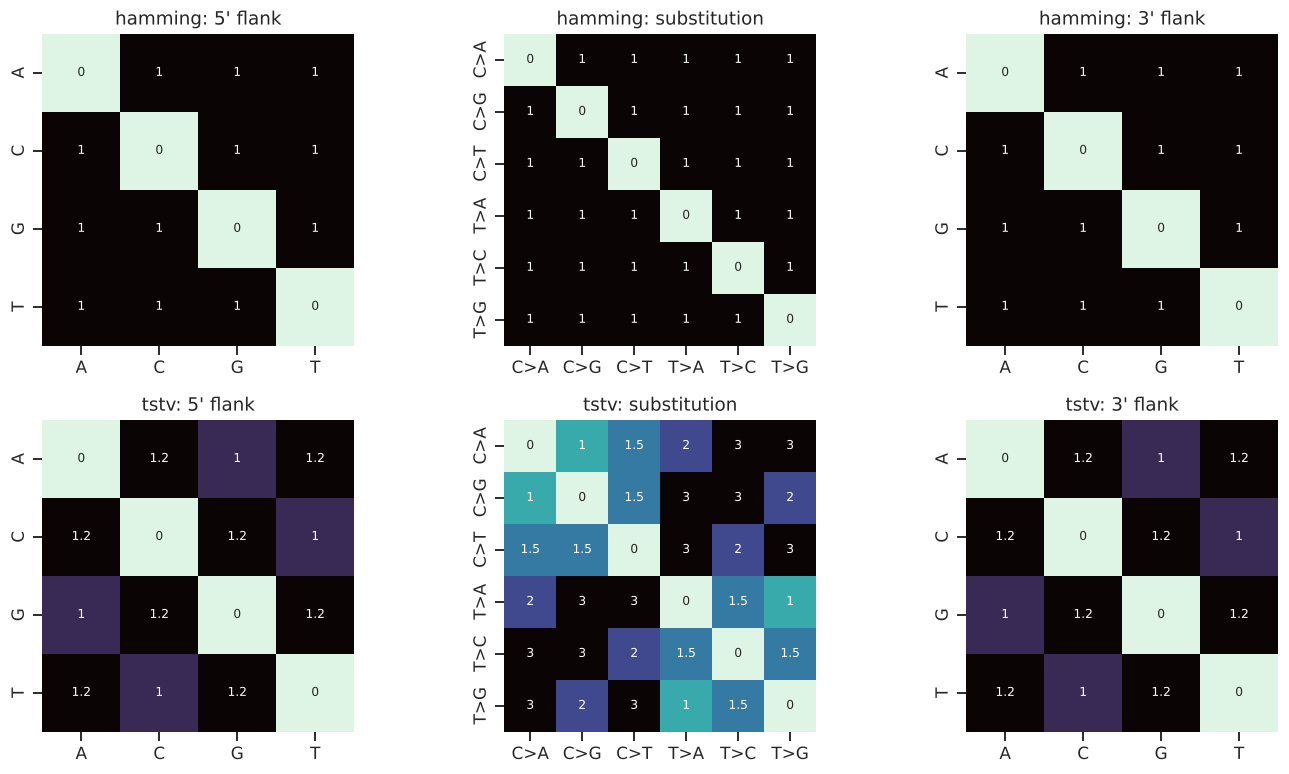

In [5]:
fig, axes = plt.subplots(len(TABLES), 3, figsize=(13, 3.6 * len(TABLES)), squeeze=False)
for r, (name, T) in enumerate(TABLES.items()):
    for c, (k, lab) in enumerate([("d5", "5' flank"), ("dsub", "substitution"), ("d3", "3' flank")]):
        sns.heatmap(T[k], ax=axes[r, c], annot=True, fmt=".2g", cmap="mako_r", cbar=False, square=True, annot_kws={"fontsize": 8})
        axes[r, c].set_title(f"{name}: {lab}")
plt.tight_layout()

## 3. Checks

In [6]:
def check_metric(C, name):
    M = C.values
    off = M[~np.eye(96, dtype=bool)]
    return {"name": name, "symmetric": np.allclose(M, M.T), "zero diagonal": np.allclose(np.diag(M), 0),
            "positive off-diag": (off > 0).all(),
            "triangle inequality": (M[:, :, None] <= M[:, None, :] + M.T[None, :, :] + 1e-9).all(),
            "min off-diag": off.min(), "max": M.max(), "distinct values": np.unique(M.round(6)).size}

pd.DataFrame([check_metric(C, k) for k, C in COSTS.items()]).set_index("name")

,symmetric,zero diagonal,positive off-diag,triangle inequality,min off-diag,max,distinct values
name,,,,,,,
hamming,True,True,True,True,1.0,4.0,5
tstv,True,True,True,True,1.0,8.5,22


In [7]:
# Sanity: the cost decomposes exactly into the three components
name = "tstv"
for a, b in [("A[C>T]G", "A[C>T]A"), ("A[C>T]G", "T[T>A]T"), ("C[C>A]A", "T[T>G]G")]:
    T = TABLES[name]; ca, cb = channels.loc[a], channels.loc[b]
    parts = (A5 * T["d5"].at[ca.five, cb.five], A_SUB * T["dsub"].at[ca["sub"], cb["sub"]], A3 * T["d3"].at[ca.three, cb.three])
    print(f"{a} -> {b}: {COSTS[name].at[a, b]:.2f} = 5' {parts[0]:.2f} + sub {parts[1]:.2f} + 3' {parts[2]:.2f}")

A[C>T]G -> A[C>T]A: 1.00 = 5' 0.00 + sub 0.00 + 3' 1.00
A[C>T]G -> T[T>A]T: 8.50 = 5' 1.25 + sub 6.00 + 3' 1.25
C[C>A]A -> T[T>G]G: 8.00 = 5' 1.00 + sub 6.00 + 3' 1.00


## 4. Visual comparison

Heatmaps (cost scaled to max 1) and metric MDS of the channels. If `03` has been run, its graph costs are shown alongside.

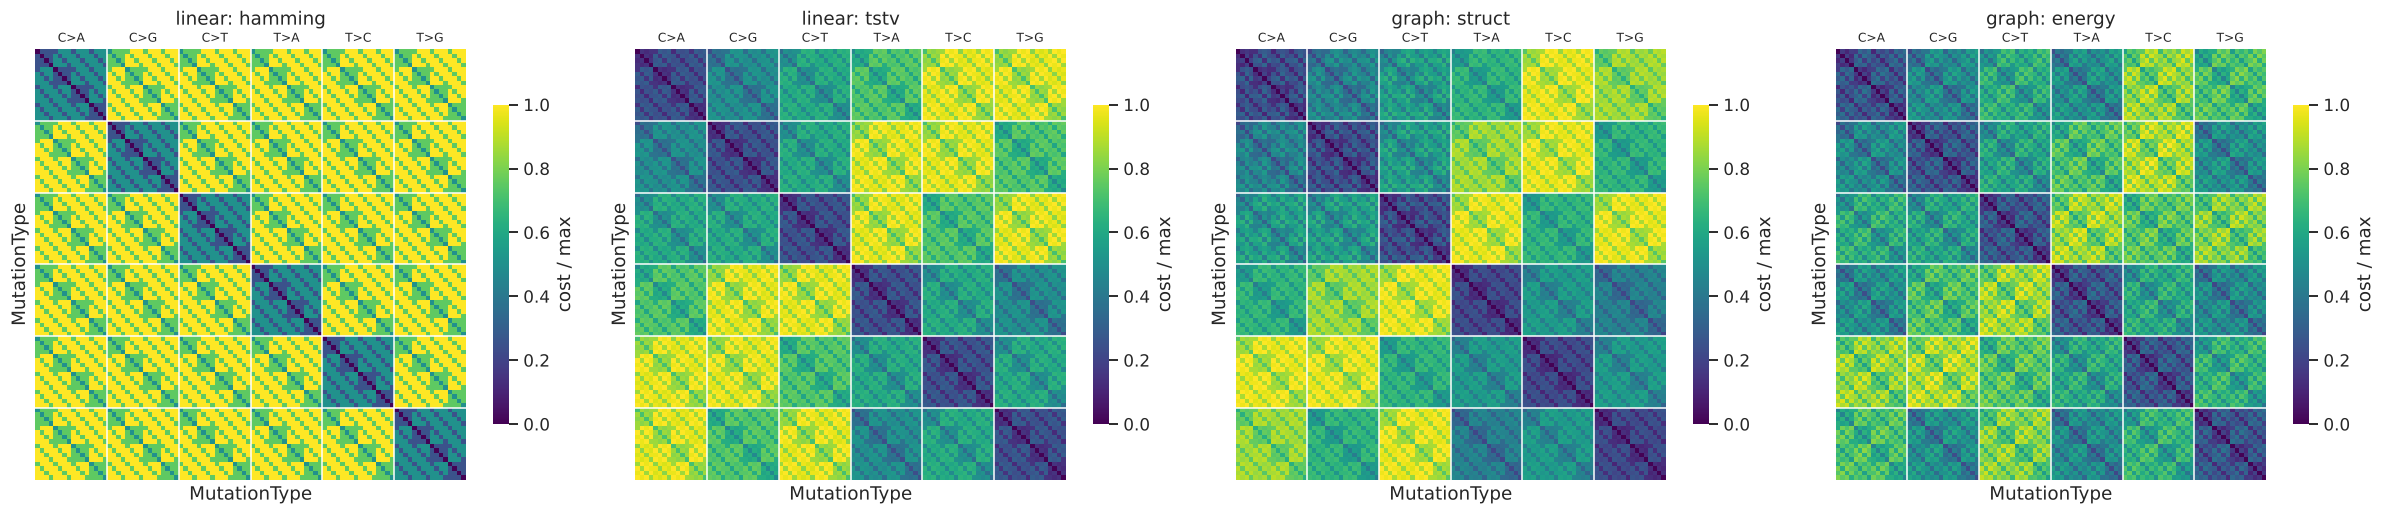

In [8]:
def cost_heatmap(C, ax, title):
    sns.heatmap(C / C.values.max(), ax=ax, cmap="viridis", square=True, xticklabels=False, yticklabels=False,
                cbar_kws={"shrink": 0.6, "label": "cost / max"})
    for i in range(1, 6):
        ax.axvline(16 * i, c="white", lw=1); ax.axhline(16 * i, c="white", lw=1)
    for i, s in enumerate(SUBS):
        ax.text(16 * i + 8, -1, s, ha="center", va="bottom", fontsize=8)
    ax.set_title(title, pad=16)

SHOW = {f"linear: {k}": C for k, C in COSTS.items()}
for tag in ["graph_struct", "graph_energy"]:
    f = OUT / f"C_{tag}.csv"
    if f.exists():
        SHOW[tag.replace("_", ": ")] = pd.read_csv(f, index_col=0).loc[CHANNELS, CHANNELS]

fig, axes = plt.subplots(1, len(SHOW), figsize=(5.5 * len(SHOW), 5.2), squeeze=False)
for ax, (k, C) in zip(axes[0], SHOW.items()):
    cost_heatmap(C, ax, k)
plt.tight_layout()

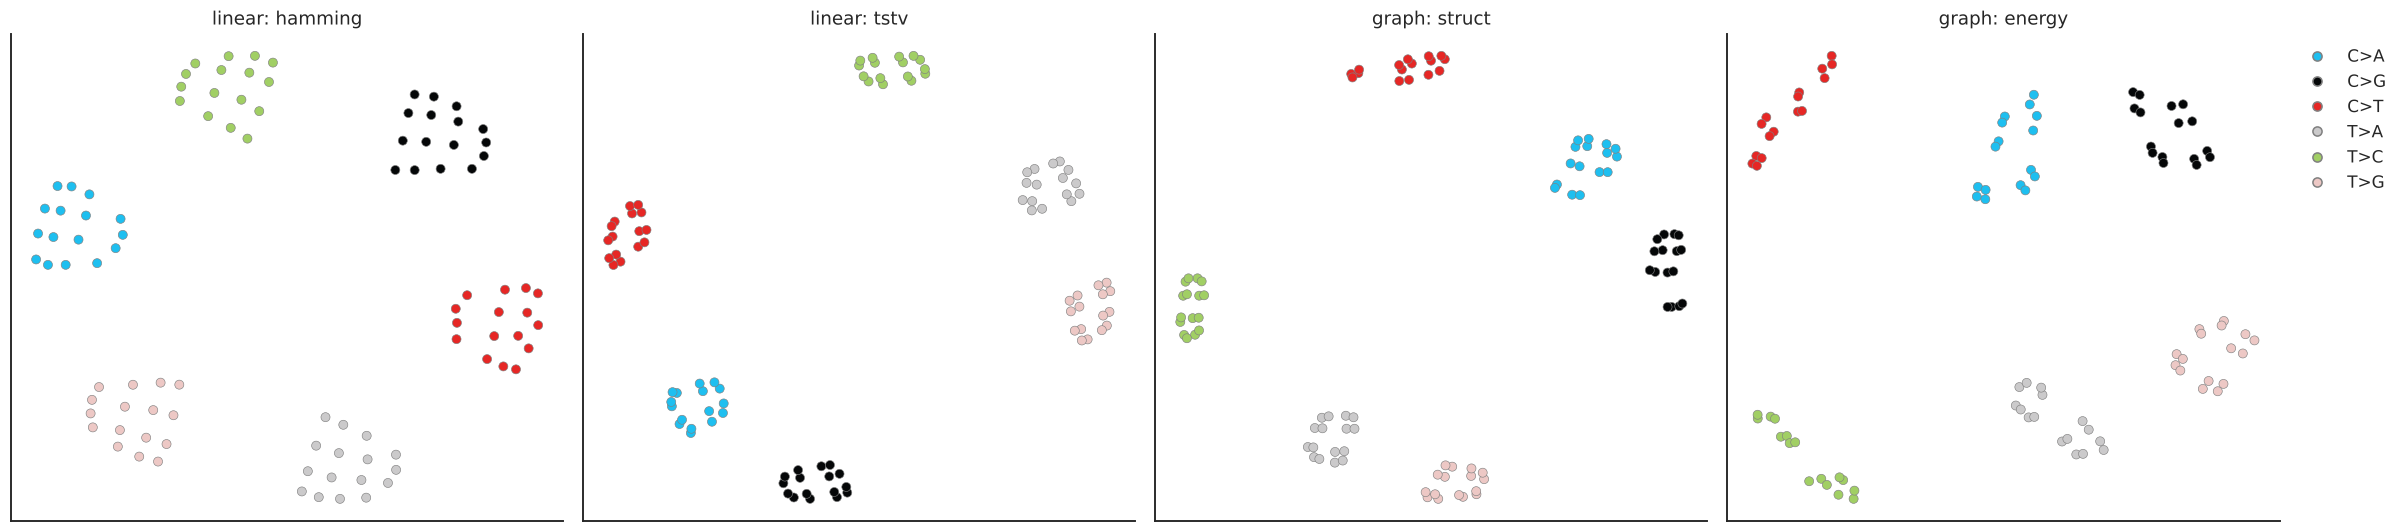

In [9]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

fig, axes = plt.subplots(1, len(SHOW), figsize=(5.5 * len(SHOW), 5), squeeze=False)
for ax, (k, C) in zip(axes[0], SHOW.items()):
    Z = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=4).fit_transform(C.values)
    ax.scatter(Z[:, 0], Z[:, 1], c=[SUB_COLORS[s] for s in SUB_OF], s=35, edgecolor="grey", linewidth=0.4)
    ax.set(title=k, xticks=[], yticks=[])
handles = [plt.Line2D([], [], marker="o", ls="", color=SUB_COLORS[s], markeredgecolor="grey", label=s) for s in SUBS]
axes[0, -1].legend(handles=handles, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

In [10]:
if len(SHOW) > len(COSTS):
    iu = np.triu_indices(96, 1)
    keys = list(SHOW)
    R = pd.DataFrame([[np.corrcoef(SHOW[a].values[iu], SHOW[b].values[iu])[0, 1] for b in keys] for a in keys], index=keys, columns=keys)
    display(R.round(3).style.background_gradient(cmap="Blues", vmin=0.5, vmax=1).set_caption("Pearson r between cost matrices (upper triangle)"))

,linear: hamming,linear: tstv,graph: struct,graph: energy
linear: hamming,1.000000,0.734000,0.690000,0.778000
linear: tstv,0.734000,1.000000,0.988000,0.919000
graph: struct,0.690000,0.988000,1.000000,0.925000
graph: energy,0.778000,0.919000,0.925000,1.000000


## 5. Save

Files are named `C_lin_<variant>.csv` (raw) and `C_lin_<variant>_scaled.csv` (max 1), in the canonical `CHANNELS` order, next to the graph costs from `03`. (`03` also writes `C_linear.csv`, its own Hamming reference; `C_lin_hamming.csv` here is the same matrix when the weights agree.)

In [11]:
for k, C in COSTS.items():
    C.to_csv(OUT / f"C_lin_{k}.csv")
    (C / C.values.max()).to_csv(OUT / f"C_lin_{k}_scaled.csv")
params = {"A5": A5, "A_SUB": A_SUB, "A3": A3, "METRIC_CLOSURE": METRIC_CLOSURE, "SYMMETRIZE": SYMMETRIZE,
          "tables": {k: {t: T[t].to_dict() for t in T} for k, T in TABLES.items()}}
(OUT / "params_linear.json").write_text(json.dumps(params, indent=2))
sorted(p.name for p in OUT.glob("C_lin_*"))

['C_lin_hamming.csv',
 'C_lin_hamming_scaled.csv',
 'C_lin_tstv.csv',
 'C_lin_tstv_scaled.csv']